Top 5 Countries by Confirmed COVID-19 Cases:
Country/Region  Total_Confirmed  Total_Deaths  Total_Recovered  Mean_Mortality_Rate  Final_Mortality_Rate (%)
        France        5863138.0      108532.0         331686.0             1.647777                  1.851091
         India        5713215.0       94030.0        5339838.0             1.199931                  1.645833
        Turkey        5235978.0       47271.0        5094279.0             1.863326                  0.902811
            UK        3910803.0      112385.0           4192.0                  inf                  2.873706
            US        3788713.0       63236.0        6399531.0             2.423976                  1.669063


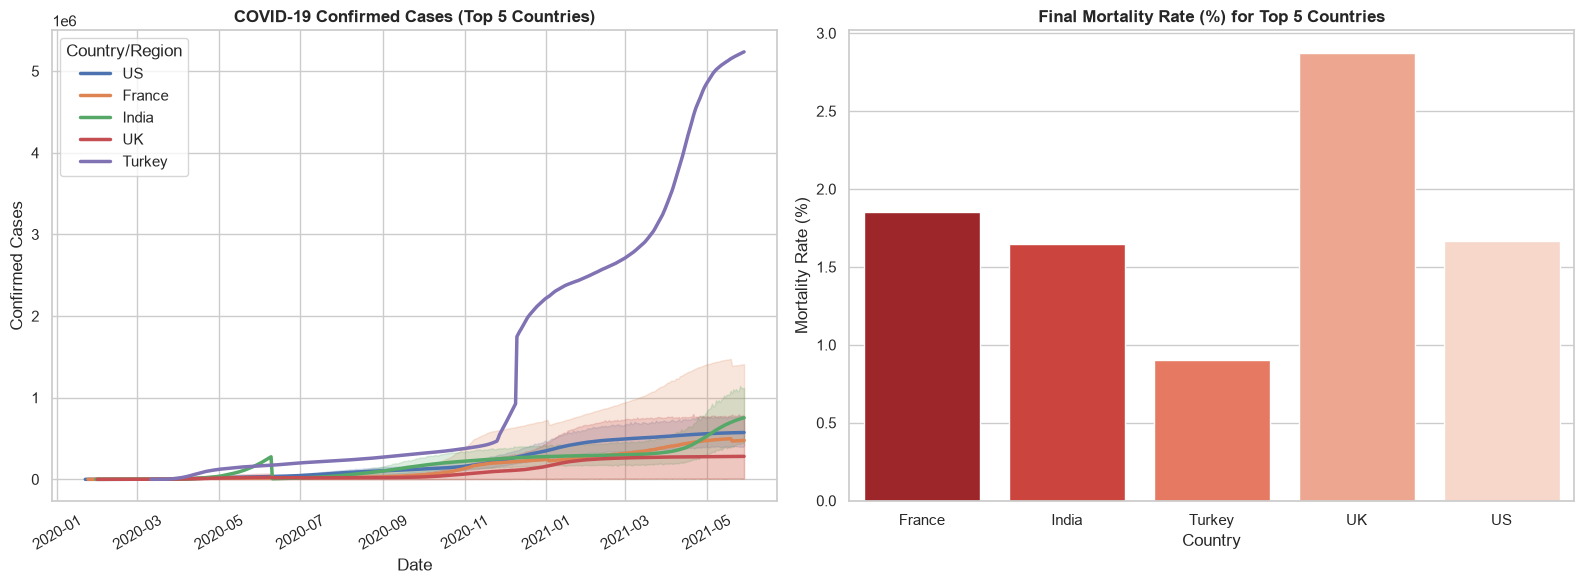

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



df_covid = pd.read_csv('covid_19_data.csv')


df_covid['ObservationDate'] = pd.to_datetime(df_covid['ObservationDate'])


df_covid['Mortality_Rate (%)'] = (df_covid['Deaths'] / df_covid['Confirmed']) * 100
df_covid['Recovery_Rate (%)'] = (df_covid['Recovered'] / df_covid['Confirmed']) * 100

df_covid.head()

country_summary = df_covid.groupby('Country/Region').agg(
    Total_Confirmed=('Confirmed', 'max'),
    Total_Deaths=('Deaths', 'max'),
    Total_Recovered=('Recovered', 'max'),
    Mean_Mortality_Rate=('Mortality_Rate (%)', 'mean')
).reset_index()


country_summary['Final_Mortality_Rate (%)'] = (country_summary['Total_Deaths'] / country_summary['Total_Confirmed']) * 100


top5_countries = country_summary.sort_values(by='Total_Confirmed', ascending=False).head(5)

print("Top 5 Countries by Confirmed COVID-19 Cases:")
print(top5_countries.to_string(index=False))

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))


top5_names = top5_countries['Country/Region'].tolist()


df_top5 = df_covid[df_covid['Country/Region'].isin(top5_names)]


sns.lineplot(
    ax=axes[0], 
    data=df_top5, 
    x='ObservationDate', 
    y='Confirmed', 
    hue='Country/Region', 
    linewidth=2.5
)
axes[0].set_title('COVID-19 Confirmed Cases (Top 5 Countries)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Confirmed Cases')
axes[0].tick_params(axis='x', rotation=30)


sns.barplot(
    ax=axes[1], 
    data=top5_countries, 
    x='Country/Region', 
    y='Final_Mortality_Rate (%)', 
    hue='Country/Region', 
    palette='Reds_r', 
    legend=False
)
axes[1].set_title('Final Mortality Rate (%) for Top 5 Countries', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Country')
axes[1].set_ylabel('Mortality Rate (%)')

plt.tight_layout()
plt.show()